In [2]:
import sys 
from pathlib import Path
sys.path.append(str(Path().cwd().parent))

import numpy as np
import matplotlib.pyplot as plt
from src.core import MeasurementStatisticsSimulator
from src.sim_funcs import perfect_poisson, perfect_entangling_noise, optimising_threshold, snr, average_error
from src.utils import plot_constant_error, dir_images

In [3]:
mu0 = 35/10
mu1 = 140/10

t_list = np.append(np.arange(0.01, 2, 0.01), np.arange(2, 7.5, 0.1))
q_list = np.arange(1, 11)

In [ ]:
entangling_noise_params = {}
ground_state_params = {"mu": mu0}
excited_state_params = {"mu": mu1}
threshold_function_params = {"mu0": mu0, "mu1": mu1}
error_function_params = {}

sim_list = []
for q in q_list:
    threshold_function_params = {"mu0": q*mu0, "mu1": q*mu1}
    sim = MeasurementStatisticsSimulator(q, perfect_entangling_noise, entangling_noise_params, perfect_poisson, ground_state_params, perfect_poisson, 
                                                         excited_state_params, optimising_threshold, dict(threshold_function_params), average_error, error_function_params)
    sim.find_k_max(t_list[-1], int(2*t_list[-1]*mu1*q), False)
    sim_list.append(sim)

In [ ]:
for sim in sim_list:
    sim.simulate(t_list)
    sim.calculate_threshold()
    sim.calculate_error()

    sim.save(f"{sim.N}q_7_5t_perfect_experimental_params.txt", mode="w")

In [4]:
def get_simulators():
    simulator_list = []
    
    for q in q_list:
        simulator = MeasurementStatisticsSimulator.load(f"{q}q_7_5t_perfect_experimental_params.txt")
        simulator_list.append(simulator)

    return simulator_list

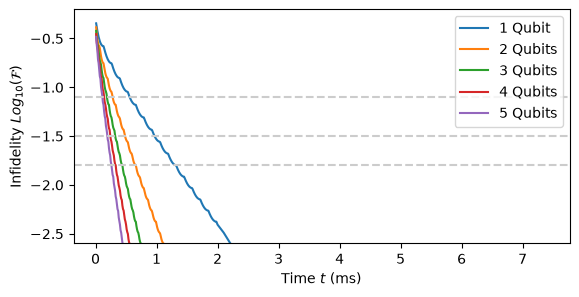

In [23]:
sim_list = get_simulators()

fontsize = 10
fig, ax = plt.subplots()
error_list = (-1.1, -1.5, -1.8)

for sim in sim_list[:5]:
    sim.plot_error(label=f"{sim.N} Qubit{'' if sim.N == 1 else 's'}", e_transform=np.log10)

for err in error_list:
    plt.axhline(y=err, color='0.8', linestyle='--')

plt.xlabel(r"Time $t$ (ms)", fontsize=fontsize)
plt.ylabel(r"Infidelity $Log_{10}(\mathcal{F})$", fontsize=fontsize)
plt.xticks(fontsize=fontsize)
plt.yticks(fontsize=fontsize)
plt.title("")
plt.legend(prop={'size': fontsize})

plt.ylim([-2.6,-0.2])
ax.set_aspect(1.6)
plt.show()

In [24]:
# fig.savefig(dir_images/"fidelity_perfect_experimental_squashed_import.svg", format="svg", dpi=300)

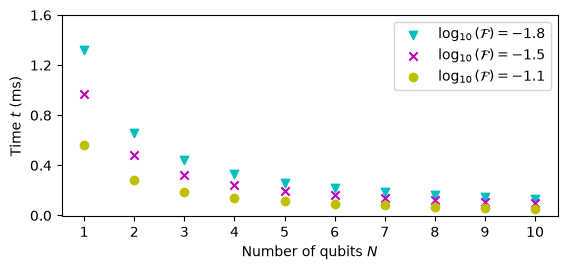

In [18]:
sim_list = get_simulators()
fontsize = 10

fig, ax = plt.subplots()
for error, color, marker in zip(10**(np.array(error_list))[::-1], ("c", "m", "y"), ("v", "x", "o")):
    plot_constant_error(sim_list, error, label=r"$\log_{10}(\mathcal{F})$"+fr"$={np.log10(error)}$", color=color, marker=marker)

plt.xlabel("Number of qubits $N$", fontsize=fontsize)
plt.ylabel("Time $t$ (ms)", fontsize=fontsize)
plt.legend(prop={'size': fontsize})
plt.xticks(range(1,11,1), fontsize=fontsize)
plt.yticks(np.arange(0,1.7,0.4), fontsize=fontsize)
ax.set_aspect(2.5)
plt.show()

In [19]:
# fig.savefig(dir_images/"fidelity_perfect_experimental_const_import.svg", format="svg", dpi=300)

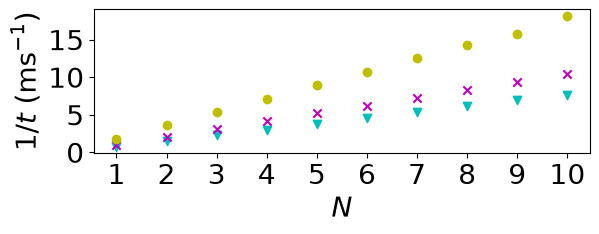

In [20]:
fontsize = 20

fig, ax = plt.subplots()
for error, color, marker in zip(10**(np.array(error_list))[::-1], ("c", "m", "y"), ("v", "x", "o")):
    plot_constant_error(sim_list, error, False, True, color=color, marker=marker)

plt.xlabel("$N$", fontsize=fontsize)
plt.ylabel("$1/t$ (ms$^{-1}$)", fontsize=fontsize)
plt.xticks(range(1,11,1), fontsize=fontsize)
plt.yticks(fontsize=fontsize)

ax.set_aspect(0.15)
plt.show()

In [21]:
# fig.savefig(dir_images/"fidelity_perfect_experimental_const_inset_squashed_import.svg", format="svg", dpi=300)

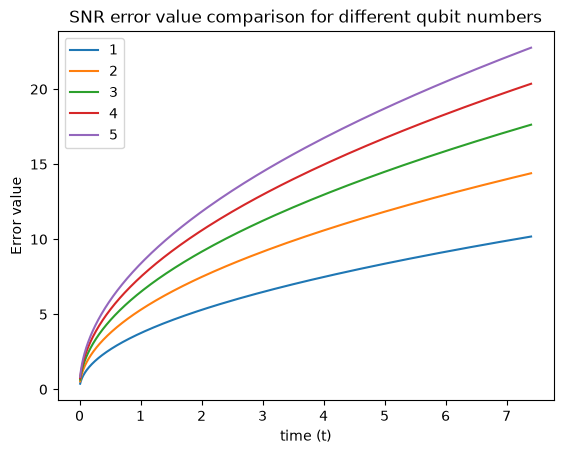

In [22]:
#Check SNR is as expected
sim_list = get_simulators()

for sim in sim_list[:5]:
    sim.error_function = snr
    sim.error_function_params = {}
    sim.calculate_error()
    sim.plot_error(label=f"{sim.N}")

plt.legend()
plt.title("SNR error value comparison for different qubit numbers")
plt.show()